In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

IMG_SIZE = 224
NUM_CLASSES = 8
SEED = 42
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow together
base = EfficientNetB0(include_top=False, weights="imagenet",
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False  # stage 1: train only the new head

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(255.0)(inputs)      # our [0,1] pipeline -> EfficientNet's expected 0-255
x = base(x, training=False)              # keeps BatchNorm in inference mode while frozen
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)               # starting value, to tune later
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

I0000 00:00:1791349317.789181   13947 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791349318.014413   13947 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791349319.513378   13947 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791349321.524496   13947 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2638 MB mem

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [2]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [3]:
!mkdir -p ../src

In [4]:
import sys
sys.path.append("../src")   # lets the notebook import from the src folder

import pipeline

train_ds = pipeline.make_dataset(pipeline.train_df, shuffle=True, augment_data=True)
val_ds = pipeline.make_dataset(pipeline.val_df, shuffle=False, augment_data=False)

print("Train:", len(pipeline.train_df), "| Val:", len(pipeline.val_df))

for images, batch_labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", batch_labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Train: 50928 | Val: 12732
Batch images shape: (32, 224, 224, 3)
Batch labels shape: (32,)
Pixel range: 0.0 to 1.0


In [5]:
import os
os.makedirs("../models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/stage1_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/stage1_log.csv"),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
)

/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5


I0000 00:00:1791349330.042098   14065 service.cc:153] XLA service 0x774e980664d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791349330.042158   14065 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3080, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791349330.370019   14065 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791349331.499417   14065 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791349331.723967   14065 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_15995__.250
E0000 00:00:1791349334.325806   14065 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791349337.496036   14065 cuda_timer.cc:87] Delay kernel timed out: meas

1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8548 - loss: 0.4264

I0000 00:00:1791349372.773847   14067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_15995__.250
E0000 00:00:1791349374.854888   14067 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8549 - loss: 0.4261

E0000 00:00:1791349392.744016   14067 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.93025, saving model to ../models/stage1_best.keras

Epoch 1: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 70s 33ms/step - accuracy: 0.8549 - loss: 0.4261 - val_accuracy: 0.9303 - val_loss: 0.2146
Epoch 2/5
1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9024 - loss: 0.2738
Epoch 2: val_accuracy improved from 0.93025 to 0.93316, saving model to ../models/stage1_best.keras

Epoch 2: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 36s 23ms/step - accuracy: 0.9024 - loss: 0.2737 - val_accuracy: 0.9332 - val_loss: 0.1869
Epoch 3/5
1589/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9070 - loss: 0.2561
Epoch 3: val_accuracy improved from 0.93316 to 0.94054, saving model to ../models/stage1_best.keras

Epoch 3: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 36s 22ms/step - accuracy: 0.9069 - loss: 0.2562 - val_accuracy: 

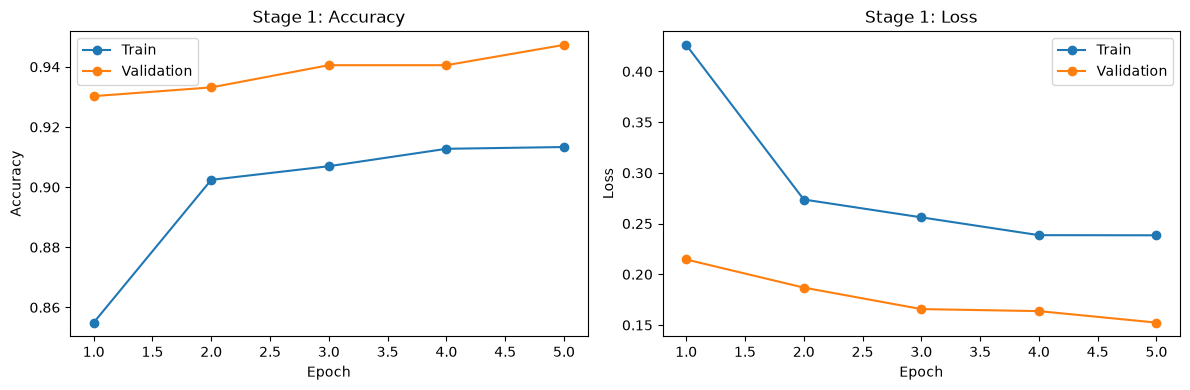

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
log = pd.read_csv("../models/stage1_log.csv")
epochs = log["epoch"] + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, log["accuracy"], marker="o", label="Train")
axes[0].plot(epochs, log["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("Stage 1: Accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

axes[1].plot(epochs, log["loss"], marker="o", label="Train")
axes[1].plot(epochs, log["val_loss"], marker="o", label="Validation")
axes[1].set_title("Stage 1: Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/stage1_curves.png", dpi=150)
plt.show()

In [7]:
# Unfreeze only the last blocks of EfficientNetB0 (block6, block7, top conv),
# keeping BatchNorm layers frozen so their statistics stay stable
base.trainable = True
for layer in base.layers:
    in_top_blocks = layer.name.startswith(("block6", "block7", "top"))
    is_bn = isinstance(layer, tf.keras.layers.BatchNormalization)
    layer.trainable = in_top_blocks and not is_bn

# Changing trainable requires recompiling, this time with a much lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
total = model.count_params()
print(f"Trainable params: {trainable:,} of {total:,}")

Trainable params: 3,140,132 of 4,059,819


In [8]:
callbacks2 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/stage2_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/stage2_log.csv"),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6, verbose=1),
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks2,
)

Epoch 1/12


/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791349547.333219   14062 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_79780__.250
E0000 00:00:1791349549.226431   14062 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9577 - loss: 0.1202

I0000 00:00:1791349592.497661   14066 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_79780__.250
E0000 00:00:1791349593.838372   14066 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9578 - loss: 0.1201
Epoch 1: val_accuracy improved from None to 0.98445, saving model to ../models/stage2_best.keras

Epoch 1: finished saving model to ../models/stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 72s 35ms/step - accuracy: 0.9578 - loss: 0.1201 - val_accuracy: 0.9844 - val_loss: 0.0454 - learning_rate: 1.0000e-04
Epoch 2/12
1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9809 - loss: 0.0556
Epoch 2: val_accuracy improved from 0.98445 to 0.98563, saving model to ../models/stage2_best.keras

Epoch 2: finished saving model to ../models/stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.9809 - loss: 0.0556 - val_accuracy: 0.9856 - val_loss: 0.0392 - learning_rate: 1.0000e-04
Epoch 3/12
1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9860 - loss: 0.0411
Epoch 3: val_accuracy improved from 0.98563 to 0.99042, saving model to ../models/stage2_best.keras

Epoch 3: finished savi

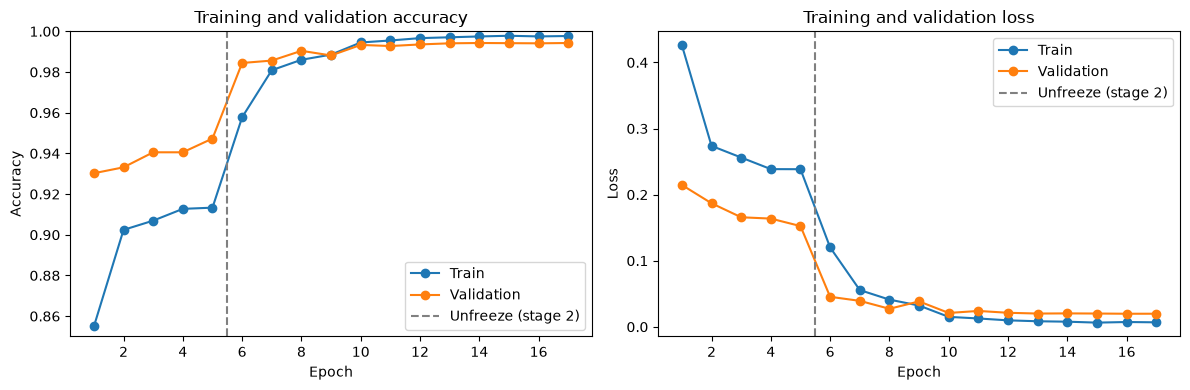

In [9]:
log1 = pd.read_csv("../models/stage1_log.csv")
log2 = pd.read_csv("../models/stage2_log.csv")
full = pd.concat([log1, log2], ignore_index=True)
epochs = range(1, len(full) + 1)
boundary = len(log1) + 0.5  # between last stage 1 and first stage 2 epoch

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (train_col, val_col, title) in zip(
    axes,
    [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")],
):
    ax.plot(epochs, full[train_col], marker="o", label="Train")
    ax.plot(epochs, full[val_col], marker="o", label="Validation")
    ax.axvline(boundary, color="grey", linestyle="--", label="Unfreeze (stage 2)")
    ax.set_title(f"Training and validation {title.lower()}")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title); ax.legend()

axes[0].set_ylim(0.85, 1.0)  # zoom so the stage 2 detail is visible

plt.tight_layout()
plt.savefig("../figures/combined_curves.png", dpi=150)
plt.show()

Validation loss: 0.0197 | Validation accuracy: 0.9941

              precision    recall  f1-score   support

      CatEye     0.9975    0.9960    0.9968      2777
     CatFace     1.0000    0.9993    0.9996      1388
    CatMouth     0.9800    0.9878    0.9839      1388
     CatNose     0.9869    0.9770    0.9819      1389
      DogEye     0.9948    0.9983    0.9966      2316
     DogFace     1.0000    1.0000    1.0000      1158
    DogMouth     0.9974    0.9948    0.9961      1158
     DogNose     0.9940    0.9965    0.9953      1158

    accuracy                         0.9941     12732
   macro avg     0.9938    0.9937    0.9938     12732
weighted avg     0.9941    0.9941    0.9941     12732



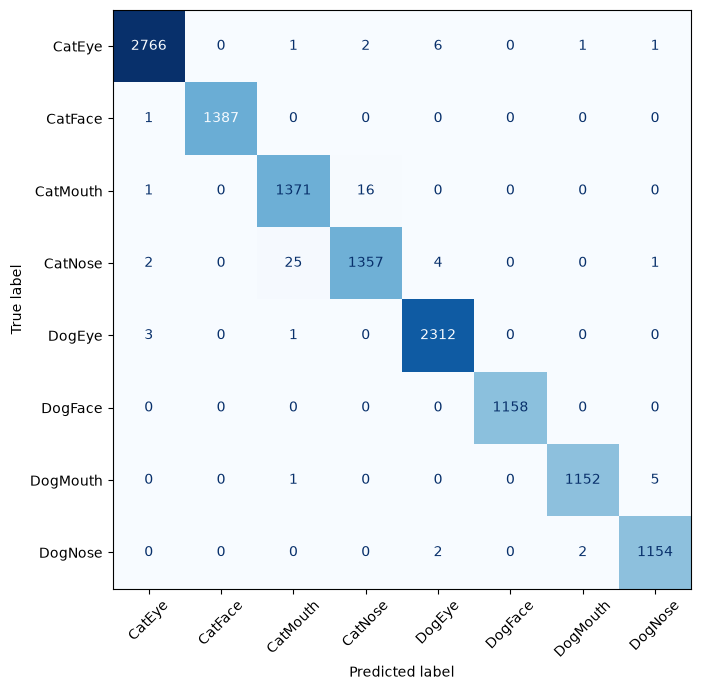

In [10]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation loss: {val_loss:.4f} | Validation accuracy: {val_acc:.4f}\n")

probs = model.predict(val_ds, verbose=0)
np.save("../models/val_probs.npy", probs)   # kept for misclassification analysis later
y_pred = probs.argmax(axis=1)
y_true = pipeline.val_df["label"].values    # same order as val_ds (it is not shuffled)

print(classification_report(y_true, y_pred,
                            target_names=pipeline.class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=pipeline.class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.tight_layout()
plt.savefig("../figures/confusion_matrix.png", dpi=150)
plt.show()

In [11]:
test_ds = pipeline.make_test_dataset()
test_probs = model.predict(test_ds, verbose=1)
np.save("../models/test_probs.npy", test_probs)

submission = pd.DataFrame({
    "image_id": pipeline.test_df["image_id"].values,   # original unpadded ids, as in sample_submission
    "class": [pipeline.idx_to_class[i] for i in test_probs.argmax(axis=1)],
})
os.makedirs("../submissions", exist_ok=True)
submission.to_csv("../submissions/submission_v1_effnetb0.csv", index=False)

sample = pd.read_csv("../data/sample_submission.csv")
print("Shape:", submission.shape, "| expected:", sample.shape)
print("Columns match:", list(submission.columns) == list(sample.columns))
print("IDs match, same order:", (submission["image_id"].values == sample["image_id"].values).all())
print(submission["class"].value_counts())
submission.head()

921/921 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step
Shape: (29443, 2) | expected: (29443, 2)
Columns match: True
IDs match, same order: True
class
CatEye      6362
DogEye      5529
CatMouth    3181
CatFace     3114
CatNose     2968
DogFace     2794
DogMouth    2762
DogNose     2733
Name: count, dtype: int64


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


In [12]:
val_conf = np.load("../models/val_probs.npy").max(axis=1)
test_conf = np.load("../models/test_probs.npy").max(axis=1)

for thr in (0.9, 0.99):
    print(f"Confidence < {thr}: val {np.mean(val_conf < thr):.2%} | test {np.mean(test_conf < thr):.2%}")
print(f"Mean confidence: val {val_conf.mean():.4f} | test {test_conf.mean():.4f}")

Confidence < 0.9: val 1.04% | test 2.61%
Confidence < 0.99: val 2.45% | test 5.06%
Mean confidence: val 0.9966 | test 0.9914


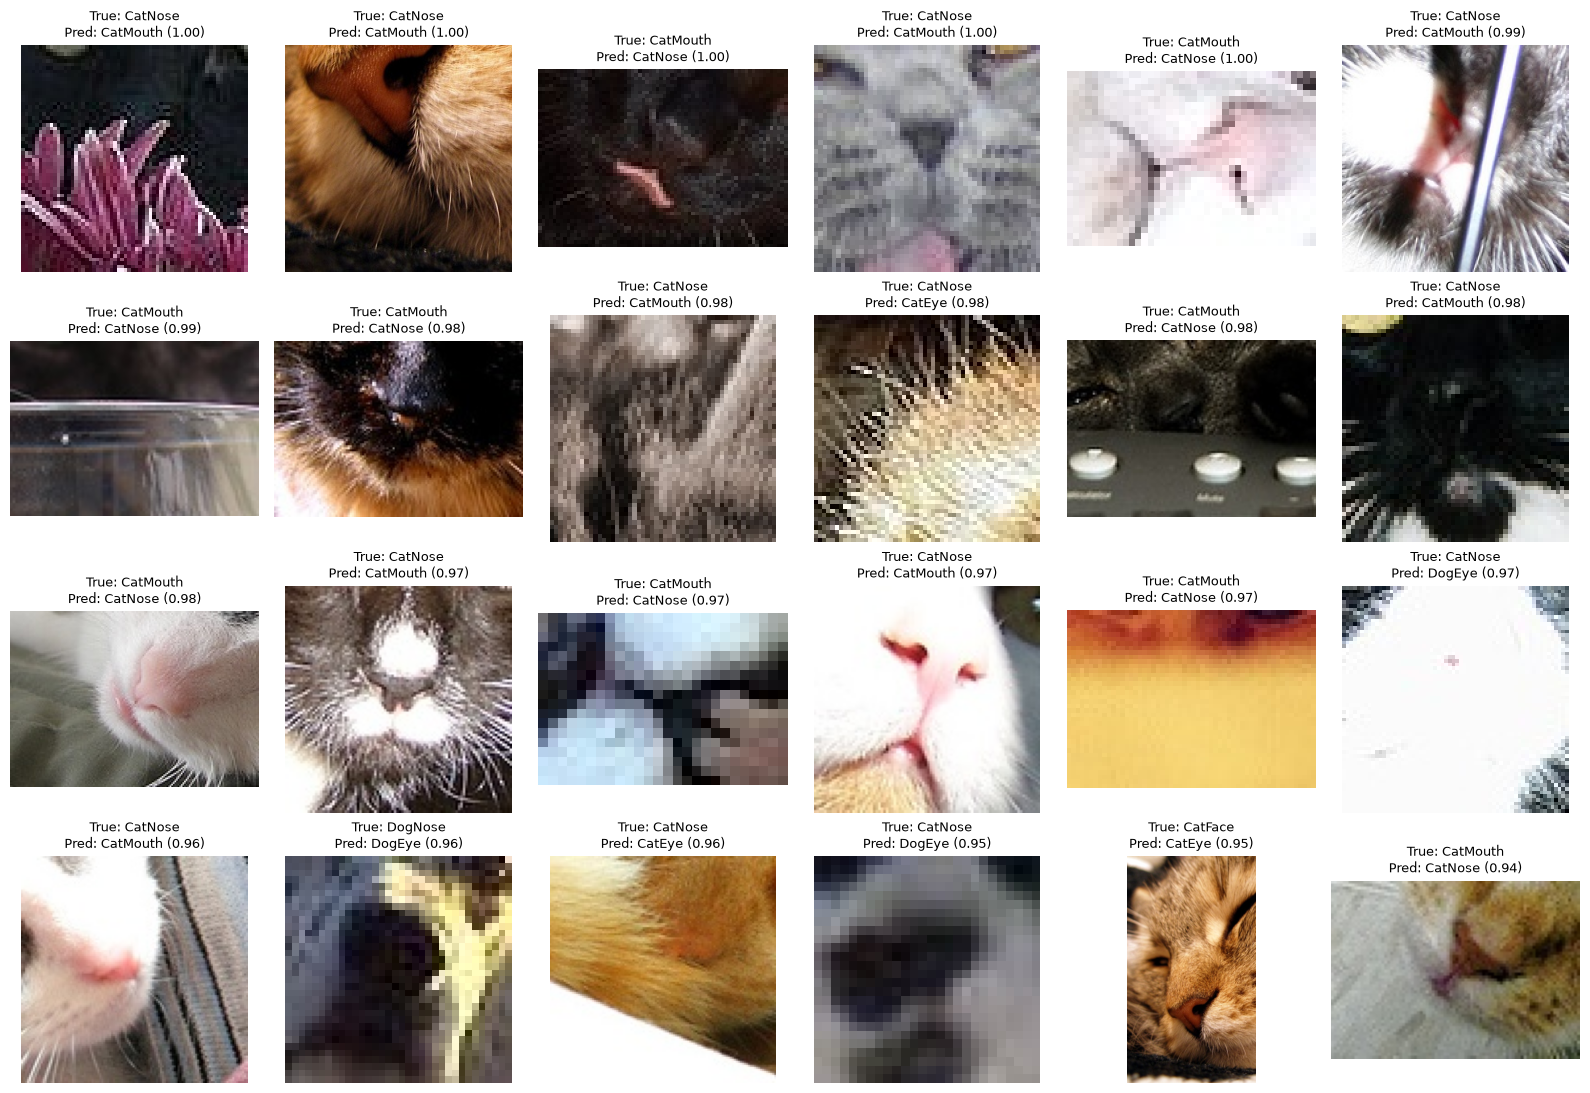

In [13]:
import matplotlib.image as mpimg

val_probs = np.load("../models/val_probs.npy")
y_pred = val_probs.argmax(axis=1)
y_true = pipeline.val_df["label"].values

wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-val_probs[wrong].max(axis=1))][:24]   # most confident mistakes first

fig, axes = plt.subplots(4, 6, figsize=(16, 11))
for ax, i in zip(axes.ravel(), wrong):
    fname = pipeline.val_df["filename"].iloc[i]
    ax.imshow(mpimg.imread(f"{pipeline.TRAIN_DIR}/{fname}"))
    ax.set_title(f"True: {pipeline.idx_to_class[y_true[i]]}\n"
                 f"Pred: {pipeline.idx_to_class[y_pred[i]]} ({val_probs[i].max():.2f})",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../figures/val_misclassified.png", dpi=150)
plt.show()

In [14]:
from PIL import Image

val = pipeline.val_df.copy()
val["pred"] = np.load("../models/val_probs.npy").argmax(axis=1)
val["wrong"] = val["pred"] != val["label"]

def short_side(fname):
    with Image.open(f"{pipeline.TRAIN_DIR}/{fname}") as im:
        return min(im.size)

val["short_side"] = val["filename"].apply(short_side)
val["size_bucket"] = pd.cut(val["short_side"], [0, 32, 64, 128, 256, 10000],
                            labels=["<=32", "33-64", "65-128", "129-256", ">256"])

summary = val.groupby("size_bucket", observed=True)["wrong"].agg(["count", "sum", "mean"])
summary.columns = ["images", "errors", "error_rate"]
summary["error_rate"] = (summary["error_rate"] * 100).round(2)
print(summary)

             images  errors  error_rate
size_bucket                            
<=32           1001      19        1.90
33-64          3925      29        0.74
65-128         4766      17        0.36
129-256        2324       9        0.39
>256            716       1        0.14


In [15]:
val_probs = np.load("../models/val_probs.npy")
y_true = pipeline.val_df["label"].values

val_ds_flip = pipeline.make_dataset(pipeline.val_df, shuffle=False, augment_data=False)
val_ds_flip = val_ds_flip.map(lambda x, y: (tf.image.flip_left_right(x), y))
probs_flip = model.predict(val_ds_flip, verbose=0)
probs_tta = (val_probs + probs_flip) / 2

for name, p in [("Single pass", val_probs), ("Flip TTA", probs_tta)]:
    print(f"{name}: accuracy {np.mean(p.argmax(axis=1) == y_true):.4f}")

Single pass: accuracy 0.9941
Flip TTA: accuracy 0.9944


In [16]:
from tensorflow.keras.applications import ResNet50V2

base_r50 = ResNet50V2(include_top=False, weights="imagenet",
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_r50.trainable = False   # stage 1: train only the new head

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)   # our [0,1] -> [-1,1], what ResNet50V2 expects
x = base_r50(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model_r50 = models.Model(inputs, outputs)
model_r50.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_r50.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │        16,392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,581,192 (89.96 MB)

 Trainable params: 16,392 (64.03 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [17]:
callbacks_r50_s1 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/r50_stage1_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/r50_stage1_log.csv"),
]

history_r50_s1 = model_r50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_r50_s1,
)

Epoch 1/5


/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791350108.534283   14066 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_225799__.165


1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8994 - loss: 0.2742

I0000 00:00:1791350153.575851   14067 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_225799__.165


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8994 - loss: 0.2741
Epoch 1: val_accuracy improved from None to 0.95382, saving model to ../models/r50_stage1_best.keras

Epoch 1: finished saving model to ../models/r50_stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 68s 37ms/step - accuracy: 0.8994 - loss: 0.2741 - val_accuracy: 0.9538 - val_loss: 0.1267
Epoch 2/5
1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9381 - loss: 0.1719
Epoch 2: val_accuracy improved from 0.95382 to 0.96073, saving model to ../models/r50_stage1_best.keras

Epoch 2: finished saving model to ../models/r50_stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 46s 29ms/step - accuracy: 0.9381 - loss: 0.1718 - val_accuracy: 0.9607 - val_loss: 0.1104
Epoch 3/5
1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9415 - loss: 0.1598
Epoch 3: val_accuracy improved from 0.96073 to 0.96395, saving model to ../models/r50_stage1_best.keras

Epoch 3: finished saving model to ../models/r50_stage1_best.

In [18]:
base_r50.trainable = True
for layer in base_r50.layers:
    in_last_stage = layer.name.startswith("conv5")
    is_bn = isinstance(layer, tf.keras.layers.BatchNormalization)
    layer.trainable = in_last_stage and not is_bn

model_r50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

trainable = sum(tf.size(w).numpy() for w in model_r50.trainable_weights)
print(f"Trainable params: {trainable:,} of {model_r50.count_params():,}")

Trainable params: 14,966,792 of 23,581,192


In [19]:
callbacks_r50_s2 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/r50_stage2_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/r50_stage2_log.csv"),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6, verbose=1),
]

history_r50_s2 = model_r50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_r50_s2,
)

Epoch 1/12


I0000 00:00:1791350375.516195   14062 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_280547__.165
W0000 00:00:1791350386.032074   14062 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.51GiB (rounded to 4844683776)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1791350386.033218   14062 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1791350386.033223   14062 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 253, Chunks in use: 252. 63.2KiB allocated for chunks. 63.0KiB in use in bin. 15.2KiB client-requested in use in bin.
I0000 00:00:1791350386.033229   14062 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 97, Chunks in use: 96. 57.0KiB allocated for chunks. 56.5KiB in use in bin. 48.4KiB client-requested in use in bin

1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9681 - loss: 0.0941

I0000 00:00:1791350458.139720   14062 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_280547__.165
W0000 00:00:1791350468.287777   14062 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.26GiB (rounded to 2422342144)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1791350468.288028   14062 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1791350468.288037   14062 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 262, Chunks in use: 261. 65.5KiB allocated for chunks. 65.2KiB in use in bin. 15.2KiB client-requested in use in bin.
I0000 00:00:1791350468.288046   14062 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 97, Chunks in use: 96. 57.2KiB allocated for chunks. 56.5KiB in use in bin. 48.4KiB client-requested in use in bin

1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9681 - loss: 0.0940
Epoch 1: val_accuracy improved from None to 0.98767, saving model to ../models/r50_stage2_best.keras

Epoch 1: finished saving model to ../models/r50_stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 134s 60ms/step - accuracy: 0.9681 - loss: 0.0940 - val_accuracy: 0.9877 - val_loss: 0.0368 - learning_rate: 1.0000e-04
Epoch 2/12
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9852 - loss: 0.0452
Epoch 2: val_accuracy improved from 0.98767 to 0.98885, saving model to ../models/r50_stage2_best.keras

Epoch 2: finished saving model to ../models/r50_stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 58s 36ms/step - accuracy: 0.9852 - loss: 0.0452 - val_accuracy: 0.9888 - val_loss: 0.0361 - learning_rate: 1.0000e-04
Epoch 3/12
1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9892 - loss: 0.0319
Epoch 3: val_accuracy improved from 0.98885 to 0.98971, saving model to ../models/r50_stage2_best.keras

E

In [20]:
model_r50.save("../models/r50_final.keras")   # the restored epoch-8 weights

r50_loss, r50_acc = model_r50.evaluate(val_ds, verbose=0)
print(f"ResNet50V2 validation loss: {r50_loss:.4f} | accuracy: {r50_acc:.4f}\n")

probs_r50 = model_r50.predict(val_ds, verbose=0)
np.save("../models/val_probs_r50.npy", probs_r50)

y_true = pipeline.val_df["label"].values
probs_eff = np.load("../models/val_probs.npy")
pred_r50, pred_eff = probs_r50.argmax(axis=1), probs_eff.argmax(axis=1)
wrong_r50, wrong_eff = pred_r50 != y_true, pred_eff != y_true
print(f"EfficientNet errors: {wrong_eff.sum()} | ResNet errors: {wrong_r50.sum()} | "
      f"both wrong: {(wrong_r50 & wrong_eff).sum()}\n")

print(classification_report(y_true, pred_r50, target_names=pipeline.class_names, digits=4))

ResNet50V2 validation loss: 0.0170 | accuracy: 0.9941

EfficientNet errors: 75 | ResNet errors: 75 | both wrong: 29

              precision    recall  f1-score   support

      CatEye     0.9964    0.9971    0.9968      2777
     CatFace     1.0000    0.9993    0.9996      1388
    CatMouth     0.9814    0.9878    0.9846      1388
     CatNose     0.9869    0.9770    0.9819      1389
      DogEye     0.9948    0.9965    0.9957      2316
     DogFace     1.0000    1.0000    1.0000      1158
    DogMouth     0.9974    0.9948    0.9961      1158
     DogNose     0.9948    0.9974    0.9961      1158

    accuracy                         0.9941     12732
   macro avg     0.9940    0.9937    0.9938     12732
weighted avg     0.9941    0.9941    0.9941     12732



In [21]:
from sklearn.metrics import log_loss

probs_ens = (probs_eff + probs_r50) / 2
pred_ens = probs_ens.argmax(axis=1)

for name, p in [("EfficientNetB0", probs_eff), ("ResNet50V2", probs_r50), ("Ensemble", probs_ens)]:
    errs = (p.argmax(axis=1) != y_true).sum()
    print(f"{name:15s} accuracy {1 - errs/len(y_true):.4f} | errors {errs} | log loss {log_loss(y_true, p):.4f}")

EfficientNetB0  accuracy 0.9941 | errors 75 | log loss 0.0197
ResNet50V2      accuracy 0.9941 | errors 75 | log loss 0.0170
Ensemble        accuracy 0.9958 | errors 53 | log loss 0.0136


In [22]:
test_ds = pipeline.make_test_dataset()
test_probs_r50 = model_r50.predict(test_ds, verbose=1)
np.save("../models/test_probs_r50.npy", test_probs_r50)

test_probs_eff = np.load("../models/test_probs.npy")
test_probs_ens = (test_probs_eff + test_probs_r50) / 2

submission_v2 = pd.DataFrame({
    "image_id": pipeline.test_df["image_id"].values,
    "class": [pipeline.idx_to_class[i] for i in test_probs_ens.argmax(axis=1)],
})
submission_v2.to_csv("../submissions/submission_v2_ensemble.csv", index=False)

sample = pd.read_csv("../data/sample_submission.csv")
print("Shape:", submission_v2.shape, "| expected:", sample.shape)
print("Columns match:", list(submission_v2.columns) == list(sample.columns))
print("IDs match, same order:", (submission_v2["image_id"].values == sample["image_id"].values).all())
print(f"Agreement with v1 predictions: {np.mean(test_probs_ens.argmax(axis=1) == test_probs_eff.argmax(axis=1)):.2%}")
print(f"Test mean confidence: {test_probs_ens.max(axis=1).mean():.4f}")

921/921 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step
Shape: (29443, 2) | expected: (29443, 2)
Columns match: True
IDs match, same order: True
Agreement with v1 predictions: 98.84%
Test mean confidence: 0.9843


In [23]:
os.makedirs("../docs", exist_ok=True)
log_md = """# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |
"""
with open("../docs/experiment_log.md", "w") as f:
    f.write(log_md)
print(open("../docs/experiment_log.md").read())

# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |



In [24]:
import sys, subprocess

out = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                     capture_output=True, text=True).stdout
with open("../requirements.txt", "w") as f:
    f.write(out)

print(len(out.splitlines()), "packages written to ../requirements.txt\n")
key = ("tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib", "pillow")
print("\n".join(l for l in out.splitlines() if l.split("==")[0].lower() in key))

139 packages written to ../requirements.txt

keras==3.15.1
matplotlib==3.11.2
numpy==2.5.3
pandas==3.0.6
pillow==12.3.0
scikit-learn==1.9.1
tensorflow==2.21.0


In [25]:
import numpy as np, pandas as pd

for name in ("submission_v1_effnetb0.csv", "submission_v2_ensemble.csv"):
    new = pd.read_csv(f"../submissions/{name}")["class"].values
    old = pd.read_csv(f"../backup_run1/submissions/{name}")["class"].values
    print(f"{name}: rerun differs from run 1 on {(new != old).sum()} of {len(new)} test images")

y_true = pipeline.val_df["label"].values
p = {}
for tag, f in [("eff", "val_probs.npy"), ("r50", "val_probs_r50.npy")]:
    p[tag] = (np.load(f"../models/{f}"), np.load(f"../backup_run1/models/{f}"))

print()
for name, i in [("Run 1", 1), ("Rerun", 0)]:
    eff_err = (p["eff"][i].argmax(1) != y_true).sum()
    r50_err = (p["r50"][i].argmax(1) != y_true).sum()
    ens_err = (((p["eff"][i] + p["r50"][i]) / 2).argmax(1) != y_true).sum()
    print(f"{name}: validation errors  EfficientNet {eff_err} | ResNet {r50_err} | Ensemble {ens_err}")

submission_v1_effnetb0.csv: rerun differs from run 1 on 331 of 29443 test images
submission_v2_ensemble.csv: rerun differs from run 1 on 233 of 29443 test images

Run 1: validation errors  EfficientNet 73 | ResNet 63 | Ensemble 46
Rerun: validation errors  EfficientNet 75 | ResNet 75 | Ensemble 53


In [26]:
import shutil, filecmp, os

for folder in ("models", "submissions", "figures"):
    shutil.copytree(f"../{folder}", f"../backup_run2/{folder}")                      # keep the rerun's files
    shutil.copytree(f"../backup_run1/{folder}", f"../{folder}", dirs_exist_ok=True)  # restore run-1 files

mismatch = []
for folder in ("models", "submissions", "figures"):
    for f in os.listdir(f"../backup_run1/{folder}"):
        if not filecmp.cmp(f"../backup_run1/{folder}/{f}", f"../{folder}/{f}", shallow=False):
            mismatch.append(f"{folder}/{f}")
print("Files that differ from run 1 after restore:", mismatch)

Files that differ from run 1 after restore: []


In [27]:
rows = """| 7 | Rerun of #2 (EfficientNetB0, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 8 | Rerun of #4 (ResNet50V2, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 9 | Rerun of #6 (ensemble of #7 and #8) | 0.9958 | - | 53 | not submitted |

Notes: rows 7-9 are a clean rerun of the full notebook as a reproducibility check
(validation accuracy computed from the error counts). Compared with rows 2, 4 and 6,
single models varied by about +/-10 validation errors, and the ensemble was the best
entry in both runs. The rerun changed 331 (v1) and 233 (v2) of 29,443 test predictions.
"""
with open("../docs/experiment_log.md", "a") as f:
    f.write(rows)
print(open("../docs/experiment_log.md").read())

# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |
| 7 | Rerun of #2 (EfficientNetB0, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 8 | Rerun of #4 (ResNet50V2, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 9 | Rerun of #6 (ensemble of #7 and #8) | 0.9958 | - | 53 | 